<a href="https://colab.research.google.com/github/Panlyzar/project_suui2/blob/main/SUI_CV4__K_meas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📒 CVIČENÍ 4. -  K-means
---
V tomto cvičení si ukážeme **první a nejjednodušší** příklad učení bez učitele - **clustering**. Clustering, jak už název napovídá, rozděluje data do tzv. clusterů - neboli oblastí/skupin/shluků. Je to tedy určitá metoda klasifikace dat, protože roztřídí příbuzná data do stejných oblastí a označí je třídou. ⏺ Rozdíl oproti klasické klasifikaci je ten, že se clustering provádí na základě hledání vzorů v datech, tedy se například měří vzdálesnost mezi daty, a není třeba mít trénovací množinu s určenými třídami - proto **učení bez učitele**. 👨‍🏫






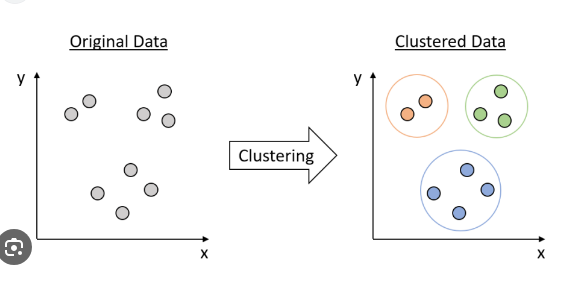

## 🧩 K-means clustering
Klasická a vcelku efektivní metoda clusterimgu se jmenuje **K-means**. Je založena na principu vytyčení **centroidů** a **měření vzdálenosti mezi daty** - doslova se měří bodová vzdálenost mezi centroidem (tedy centrálním bodem shluku) a okolními body. Měření této vzdálenosti 📐 může probíhat také různými metodami, jako je třeba euklidovská vzdálenost, manhatenská vzdálenost atd.

**Princip:**
Obvykle se kolem centroidu A vytyčí poloměr, a pokud se body nachází v rámci tohoto poloměru tak automaticky patří do shluku A 🟢 a pokud ne tak patří do jiného shkluku 🔴. Postup může být ale i ten, že se dělají malé poloměry v okolí bodů a testuje se zda se protli či nikoliv.


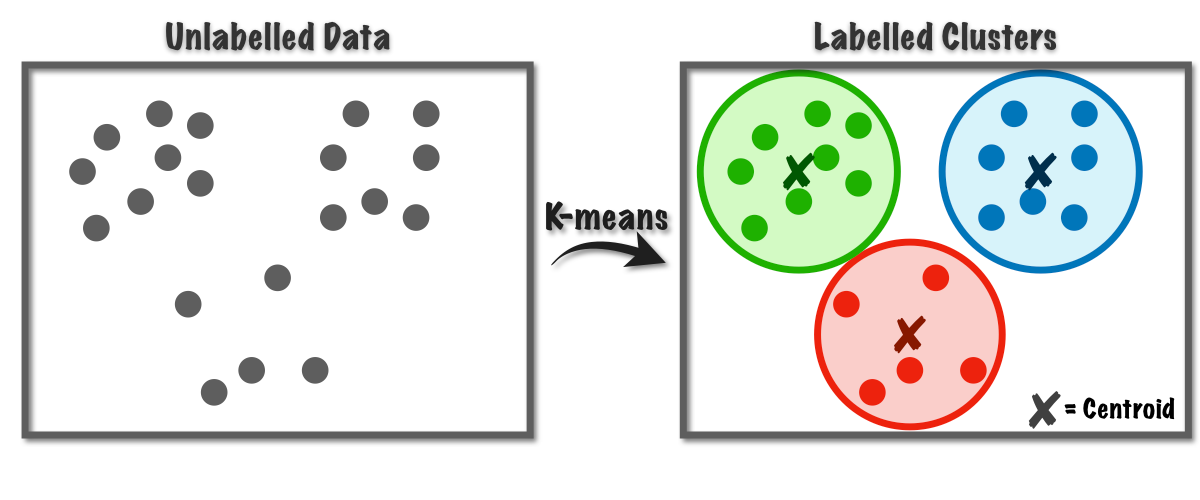

In [ ]:
# Import základních ML knihoven - best practices
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Knihovna pro práci s K-means
from sklearn.cluster import KMeans

## 📃 ČÁST 1: Příprava dat: Iris
---
Opět použijeme Iris `dataset` ať můžeme porovnat výsledky s předchozím cvičením na klasickou klasifikaci pomocí `Decision Trees`.
Použijeme *Iris* dataset který se hodí na tento typ klasifikační úlohy [(zdroj: www.lac.inpe.br)](http://www.lac.inpe.br/~rafael.santos/Docs/CAP394/WholeStory-Iris.html).

### Popis datasetu:
*Dataset Iris obsahuje čtyři rysy (délku a šířku kališních a korunních lístků) u 50 vzorků tří druhů kosatců (Iris setosa, Iris virginica a Iris versicolor). Tyto měření byla použita k vytvoření lineárního diskriminačního modelu pro klasifikaci těchto druhů. Dataset je často používán v datovém dolování, příkladech klasifikace a shlukování a k testování algoritmů.*

**Sloupce:**
- sepal.length: délka kališních lístků
- sepal.width: šířka kališních lístků
- petal.length: délka korunních lístků
- petal.width: šířka korunních lístků
- variety: druh rostliny

**Cíl:**
Hlavním cílem tohoto datasetu je rozpoznávat druh rostliny na základě délky a šířky kalačních a korunních lístků.

In [ ]:
from sklearn.datasets import load_iris
# Načtení datasetu Iris
iris = load_iris()

In [ ]:
# Převod na DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["variety"] = iris.target
df.head()

### 🔭 Explorační analýza
*Není třeba provádět, byla již provedena v předchozím cvičení.*

## ✂️ Rozdělení dat
Tentokrát nebudeme pro trénování využívat výstupy `y` ale pouze vstupy `X`. I přesto si data rozdělíme abychom mohli porovnat a otestovat jak si model bez učitele vedl. Naše testovací množina bude tedy celé `y`. 🎯

Jako vstupy `X` použijeme naměřené vlastnosti rostliny (neboli `data`) a jako výstupy `y` potřebujeme konktrétní třídu - tedy druh rostliny. Tomu odpovídá sloupec `variety` neboli `target`.

In [ ]:
# Rozdělení na X a y - vstupy a výstupy
"""
Warning:
Protože používáme preloaded Iris dataset, je rozdělení jednotuché - data a target
"""
X = iris.data
y = iris.target

# Dělení dat na trénovací a testovací, v poměru 80/20
X.shape, y.shape

In [ ]:
# Náhled dat
X[:5]

In [ ]:
y[:5]

### 🔷 Normalizace dat
Aby se model efektivněji trénoval a srovnali se případné odchylky mezi daty, je dobrou praxí jej **normalizovat**. To znamená, že všechny hodnoty "*naskelujeme*" na interval mezi `<0,1>` nebo `<-1,1>`. K tomuto využijeme funkci `normalize` či `minmax_scale` která to udělá za nás nebo to uděláme ručně, operace kterou scaler provádí je následující: `X_norm = X - min(X) / max(X) - min(X)`.

Můžeme místo normalizace použít **standartizaci**, která provádí podobnou operaci: `X_norm = X - mean(X) / sd(X)` kde `mean` je průměr a  `sd` je standartní odchylka.  



👉Hint: Rozdíl mezi `normalize` a `minmax_scale`

**Kdy co použít:**

- Chci mít všechny sloupce ve srovnatelném rozsahu (pro modely citlivé na měřítko jako k-NN, k-means, neuronky): použij `MinMaxScaler/minmax_scale` (fit na tréninku, potom transform na valid/test).

- Pracuji s vektory znaků/dokumentů a dává smysl normalizovat délku vektoru (kosinová vzdálenost, SVM s kosinovým jádrem, vyhledávání): použij `normalize` (L2).

**Důležité rozdíly:**

- *Směr operace:* minmax_scale = po sloupcích; normalize = po řádcích.

- *Reverzibilita:* MinMaxScaler má inverse_transform; Normalizer obvykle ne (ztratí se původní „délka“).

- *Citlivost na outliery:* minmax_scale ano; normalize méně (škáluje na jednotkovou délku).

- *Potřeba fit:*[ minmax_scale/MinMaxScaler](https://) ano (min/max z tréninku); normalize ne.

- *Konstantní sloupec:* u MinMaxScaler skončí typicky jako samé a (dolní hranice intervalu, obvykle 0); normalize vrátí nuly, pokud je řádek nulový.

In [ ]:
# Přéklad: normalize vs min_max
import numpy as np
from sklearn.preprocessing import minmax_scale, normalize

X_example = np.array([[1., 10.],
              [2., 20.],
              [3., 30.]])

# Min–max: škáluje sloupce do [0, 1]
X_minmax = minmax_scale(X_example, feature_range=(0, 1))

# Normalize: škáluje řádky na jednotkovou L2 normu
X_norm = normalize(X_example, norm='l2')


In [ ]:
# Normalizuje skrz sloupce
X_minmax

In [ ]:
# Normalizuje po řádcích
X_norm

### 🧠 ÚKOL 1:
Proveďte normalizaci nebo standartizaci dat (vstupů `X`) a uložte je do proměnné `X_norm`. Tyto normalizované data budou poté využity k trénování modelu. Normalizaci dat proveďte buď pomocí funkce `normalize` z knihovny `sklearn` [(online doc)](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.normalize.html), nebo pomocí `minmax_scale` [(online doc)](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.minmax_scale.html). Odůvodněte svůj výběr.






In [ ]:
# řešení úkolu č. 1:
X_norm = ???

X_norm[:5], X[:5]

In [ ]:
X_norm.min(), X_norm.max()

### ⭐ Vytvoření modelu
Dataset je připraven, nyní nám stačí vytvořit, natrénovat a otestovat model. Ještě než se do toho dáme, musíme si udělat analýzu počtu očekavaých klusterů.

#### Detekce ideálního předpokládaného počtu klusterů: *Elbow metoda*

In [ ]:
# Assuming 'data' is your dataset
wcss = [] #Within-Cluster Sum of Squares
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_norm)
    wcss.append(kmeans.inertia_)

# Plotting the elbow plot
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method for Optimal k')
plt.show()


### 🧠 ÚKOL 2:
Rozhodni jaké j ideální `k` a proč.

### 💪 Trénování modelu

In [ ]:
# Vytvoření instance K-means modelu, s ??? clustery protože očekáváme rozdělení na ??? třídy
kmeans = KMeans(n_clusters=???, n_init="auto", random_state=42)

In [ ]:
# Fit the model to the standardized data
kmeans.fit(X_norm)

In [ ]:
# Získáme natrénované třídy
y_pred = kmeans.labels_

In [ ]:
kmeans.cluster_centers_

In [ ]:
# Náhled dat
y_pred, y

✍ *Vsuvka:* Zde vidíme problém - Už první třídy nesedí! Vypadá to že **čísla klusterů a označení tříd má uplně jinou indexaci**. Lets fix it! 🔧

In [ ]:
# Předpokládejme že cluster 1 je třída 0, cluster 2 je třída 1, a cluster 0 je třída 2

# Vytáhnu si pomocí podmínek nad listy indexi položek podle hodnot 0,1,2
indicies_0 = y_pred == 1
indicies_1 = y_pred == 2
indicies_2 = y_pred == 0

# Přemapuju list pomocí mých indexů na indexaci tříd z datasetu Iris
y_pred[indicies_0] = 0
y_pred[indicies_1] = 1
y_pred[indicies_2] = 2
y_pred, y

To už vypadá mnohem lépe 😎

### ✅ Testování modelu
Model obvykle testujeme tak, že testujeme naučené (predikované) výstupy oproti skutečným. V našem případě jsou predikované třídy uloženy v poli `y_pred` a skutečné v poli `y`. Pro otestování `score` klasifikačního modelu používáme několik druhů **metrik**, například: **Accuracy** (přesnost), **Precision** (senzitivita).

### 🧠 ÚKOL 3:
Proveďte otestování modelu pomocí metriky **Accuracy** (přesnost). Využijte funkci `accuracy_score` z knihovny `sklearn` [(online doc)](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html), nebo napište vlastní funkci.





In [ ]:
#řešení úkolu č.3:
true_values = ???
accuracy = ???
accuracy

## 👁️ Vizualizace K-Means
Pro co nejlepší pochopení jak takový `K-means `vlastně funguje a co dělá, je nejlepší si ho prostě vizualizovat. Na obrázku níže vidíte modelem určené centroidy a clustery. 🟢🔴🔵

In [ ]:
# Podíváme se jaké vybral K-mens centroidy
kmeans.cluster_centers_

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

# Protože centroidy jsou ve 4 osách, je třeba vytvořit 4D graf. Podle barev bodů poznáme které body se "nalepily" na které centroidy.

# Vykreslíme vstupní data (featury)
x = X_norm[:,0]
y = X_norm[:,1]
z = X_norm[:,2]
w = X_norm[:,3]

# A centroidy
x_centroids = kmeans.cluster_centers_[:,0]
y_centroids = kmeans.cluster_centers_[:,1]
z_centroids = kmeans.cluster_centers_[:,2]
w_centroids = kmeans.cluster_centers_[:,3]

# Barvy a velikosti budů představují 4. dimenzi (w)
colors = w
sizes = w * 10

# Vytvoření 3D scatter plotů pro body a centroidy
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Atribut cmap mapuje interval <0,1> na barvu - od studené po teplou.
scatter = ax.scatter(x, y, z, c=w, s=sizes, cmap='viridis')
scatter = ax.scatter(x_centroids, y_centroids, z_centroids, c=w_centroids, s=1000, cmap='viridis')

# Přidej colorbar
plt.colorbar(scatter)

plt.show()

### 🧠 ÚKOL 4:
Napadá Vás jak lépe vizualizovat K-Means model tak aby bylo vidět do které třídy jednotlivý bod patří? Například označit třídu 0 červeně, třídu 1 zeleně a třídu 2 modře? Ideálně k tomu ještě vypsat legendu a vykreslit centroidy 🎯





In [ ]:
# řešení úkolu č. 4:
# PS: Vycházej z původního kodu výše
???

In [ ]:
# Zkuste to ještě v 2D
???

### 🧠 ÚKOL 5: Custom Clustering metoda

Zkus naimplementovat **vlastní clustering metodu**. Máš nějaký nápad jak k-means vylepšit? Lets do it! 😎🚀

PS: Pro pomoc s programováním můžeš využít libovolném jazykové modely!

In [ ]:
# Napiš metodu ideálně jako třídu s rohraním fit(), predict() a score() a plot() pro vykreslení 2D/3D grafu

# Kostra třídy
class SuperClusterMethod():
  def __init__(self, k = None, **kwargs) -> None:
    pass

  def fit(self, X_train, y_train):
    pass

  def predict(self, X_test):
    pass

  def score(self, X_test, y_test):
    pass

  def plot(self):
    pass